# 03 — Phase 3 · Experiment 1 — Binary vs multiclass (H1, Q2)

## Question
Does a binary detector that looks excellent remain useful when the task is to
identify the attack family?  Q2 asks exactly that.

## Hypothesis H1
Multiclass classification is harder than binary classification.

## Protocol
- Same deduped rows, same family-stratified 80/20 split, same seed (42), same
  three pipelines as the baseline.  Only the target changes.
- `binary`: Benign vs DDoS.
- `multiclass`: Benign + 12 CIC-DDoS2019 attack types, obtained by collapsing
  `DrDoS_X` onto `X` (13 classes).
- `multiclass_no_protocol`: same target, `Protocol` removed.  Protocol is
  almost family-deterministic, so this ablation measures how much of the
  multiclass score is protocol lookup.
- Results are produced by `uv run daf-projet exp1` and loaded from
  `results/exp1.csv`; the notebook does not retrain on a different split.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "figures"

results = pd.read_csv(RES / "exp1.csv")
per_class = pd.read_csv(RES / "exp1_per_class.csv")
display(
    results[
        [
            "task",
            "model",
            "n_classes",
            "macro_f1",
            "weighted_f1",
            "accuracy",
            "pr_auc",
            "roc_auc",
            "fpr",
            "fpr_at_tpr95",
            "fit_seconds",
            "n_features_effective",
        ]
    ].round(4)
)

,task,model,n_classes,macro_f1,weighted_f1,accuracy,pr_auc,roc_auc,fpr,fpr_at_tpr95,fit_seconds,n_features_effective
0,binary,dummy,2,0.5006,0.6507,0.6508,0.7741,0.5006,0.7736,0.9497,1.2178,65
1,binary,logreg,2,0.9949,0.9964,0.9964,0.9998,0.9994,0.0026,0.0001,5.2236,65
2,binary,random_forest,2,0.9991,0.9994,0.9994,1.0000,1.0000,0.0003,0.0000,25.6222,65
3,multiclass,dummy,13,0.0763,0.2080,0.2082,0.0768,0.4996,0.0771,0.9500,0.8657,65
4,multiclass,logreg,13,0.6029,0.9440,0.9310,0.5932,0.9887,0.0055,0.0446,298.7914,65
5,multiclass,random_forest,13,0.7566,0.9816,0.9815,0.7786,0.9945,0.0015,0.0276,22.6850,65
6,multiclass_no_protocol,dummy,13,0.0763,0.2080,0.2082,0.0768,0.4996,0.0771,0.9500,0.7282,64
7,multiclass_no_protocol,logreg,13,0.6007,0.9439,0.9308,0.5920,0.9886,0.0055,0.0450,288.3339,64
8,multiclass_no_protocol,random_forest,13,0.7577,0.9817,0.9816,0.7790,0.9948,0.0015,0.0114,22.1168,64


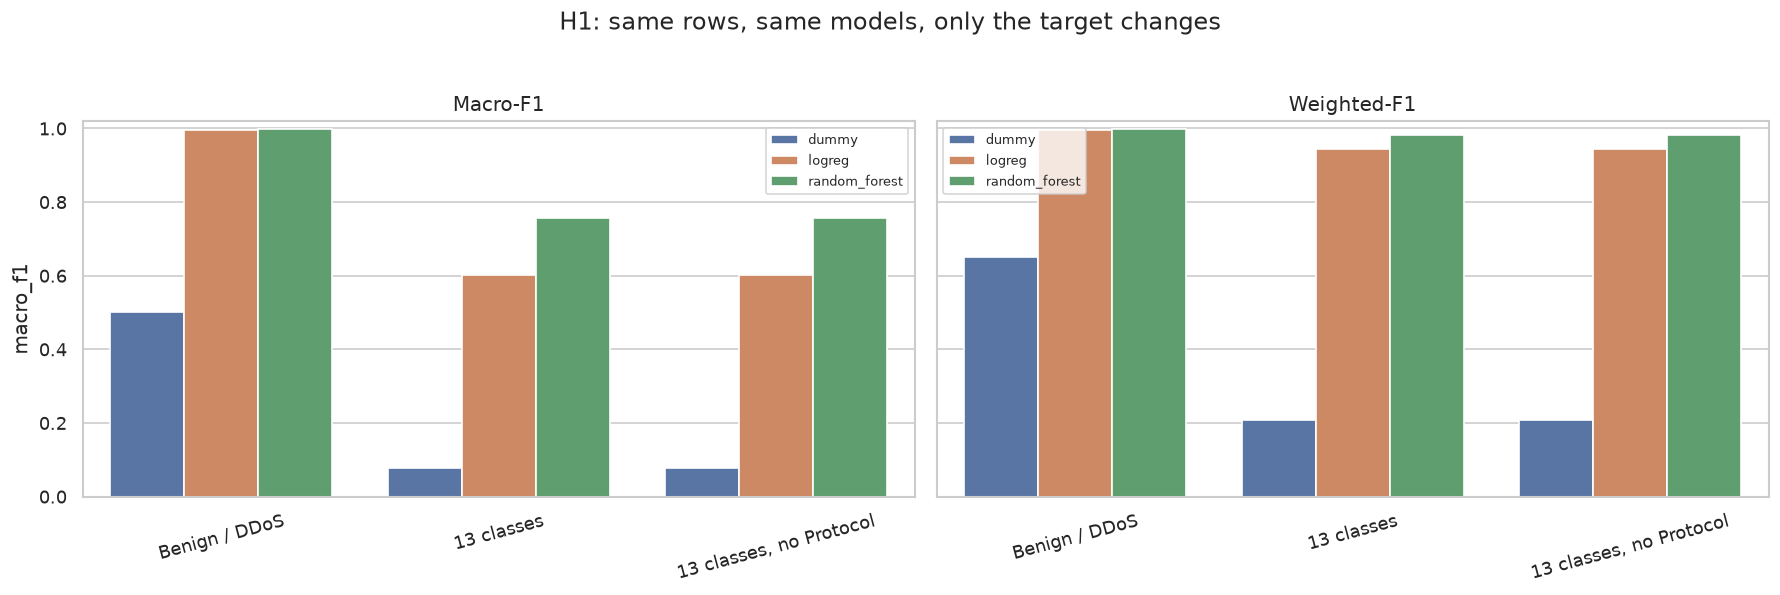

model,dummy,logreg,random_forest
task,,,
binary,0.5006,0.9949,0.9991
multiclass,0.0763,0.6029,0.7566
multiclass_no_protocol,0.0763,0.6007,0.7577


In [2]:
order = ["binary", "multiclass", "multiclass_no_protocol"]
labels = {
    "binary": "Benign / DDoS",
    "multiclass": "13 classes",
    "multiclass_no_protocol": "13 classes, no Protocol",
}
plot = results.copy()
plot["task_label"] = plot["task"].map(labels)
plot["task_label"] = pd.Categorical(plot["task_label"], categories=[labels[t] for t in order], ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, metric in zip(axes, ["macro_f1", "weighted_f1"]):
    sns.barplot(data=plot, x="task_label", y=metric, hue="model", ax=ax)
    ax.set_ylim(0, 1.02)
    ax.set_title(metric.replace("_", "-").title())
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(title="", fontsize=8)
fig.suptitle("H1: same rows, same models, only the target changes", y=1.03)
fig.tight_layout()
fig.savefig(FIG / "03_exp1_macro_weighted_f1.png", bbox_inches="tight")
plt.show()

display(
    results.pivot(index="task", columns="model", values="macro_f1")
    .reindex(order)
    .round(4)
)

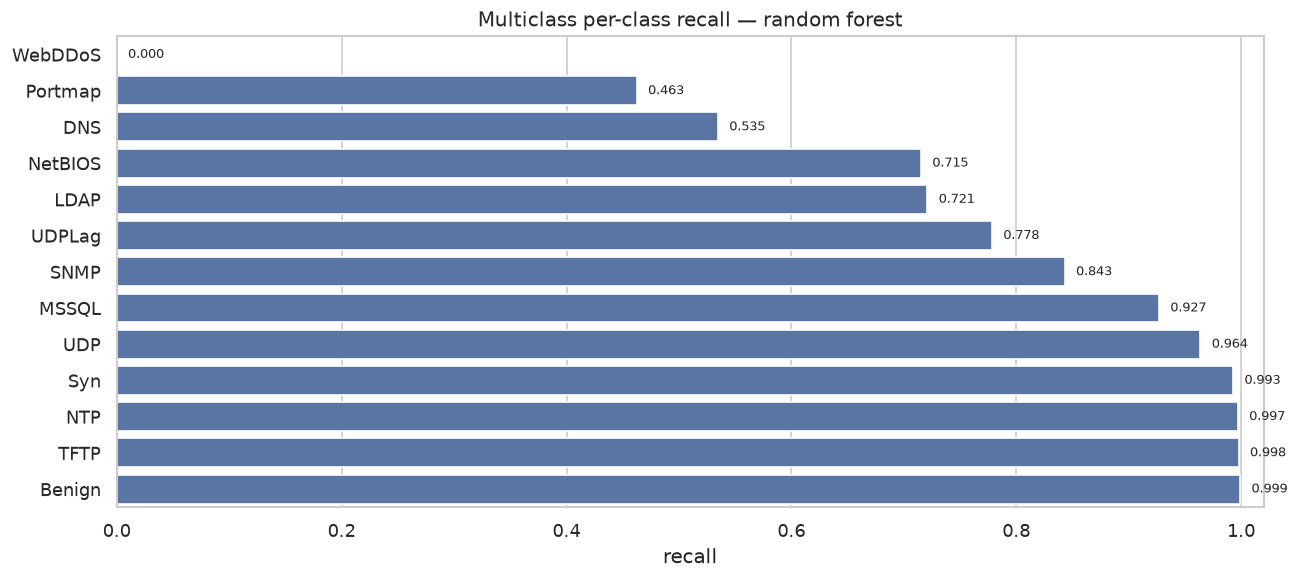

,class,precision,recall,f1,support,fpr
44,WebDDoS,0.0000,0.0000,0.0000,10,0.0002
38,Portmap,0.4512,0.4625,0.4568,80,0.0005
33,DNS,0.6101,0.5347,0.5699,720,0.0030
37,NetBIOS,0.6712,0.7153,0.6926,137,0.0006
34,LDAP,0.5509,0.7210,0.6246,405,0.0029
43,UDPLag,0.8477,0.7784,0.8116,1688,0.0029
39,SNMP,0.7826,0.8431,0.8117,427,0.0012
35,MSSQL,0.9333,0.9270,0.9301,2341,0.0019
42,UDP,0.9326,0.9638,0.9480,5443,0.0048
40,Syn,0.9966,0.9929,0.9948,9550,0.0004


In [3]:
# Per-class recall for the strongest multiclass model.
focus = per_class[
    (per_class["task"] == "multiclass") & (per_class["model"] == "random_forest")
].copy()
focus["class"] = focus["class"].astype(str)
focus = focus.sort_values("recall")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=focus, x="recall", y="class", color="#4c72b0", ax=ax)
ax.set_xlim(0, 1.02)
ax.set_title("Multiclass per-class recall — random forest")
ax.set_xlabel("recall")
ax.set_ylabel("")
for i, row in enumerate(focus.itertuples()):
    ax.text(row.recall + 0.01, i, f"{row.recall:.3f}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "03_exp1_per_class_recall.png", bbox_inches="tight")
plt.show()

display(focus[["class", "precision", "recall", "f1", "support", "fpr"]].round(4))

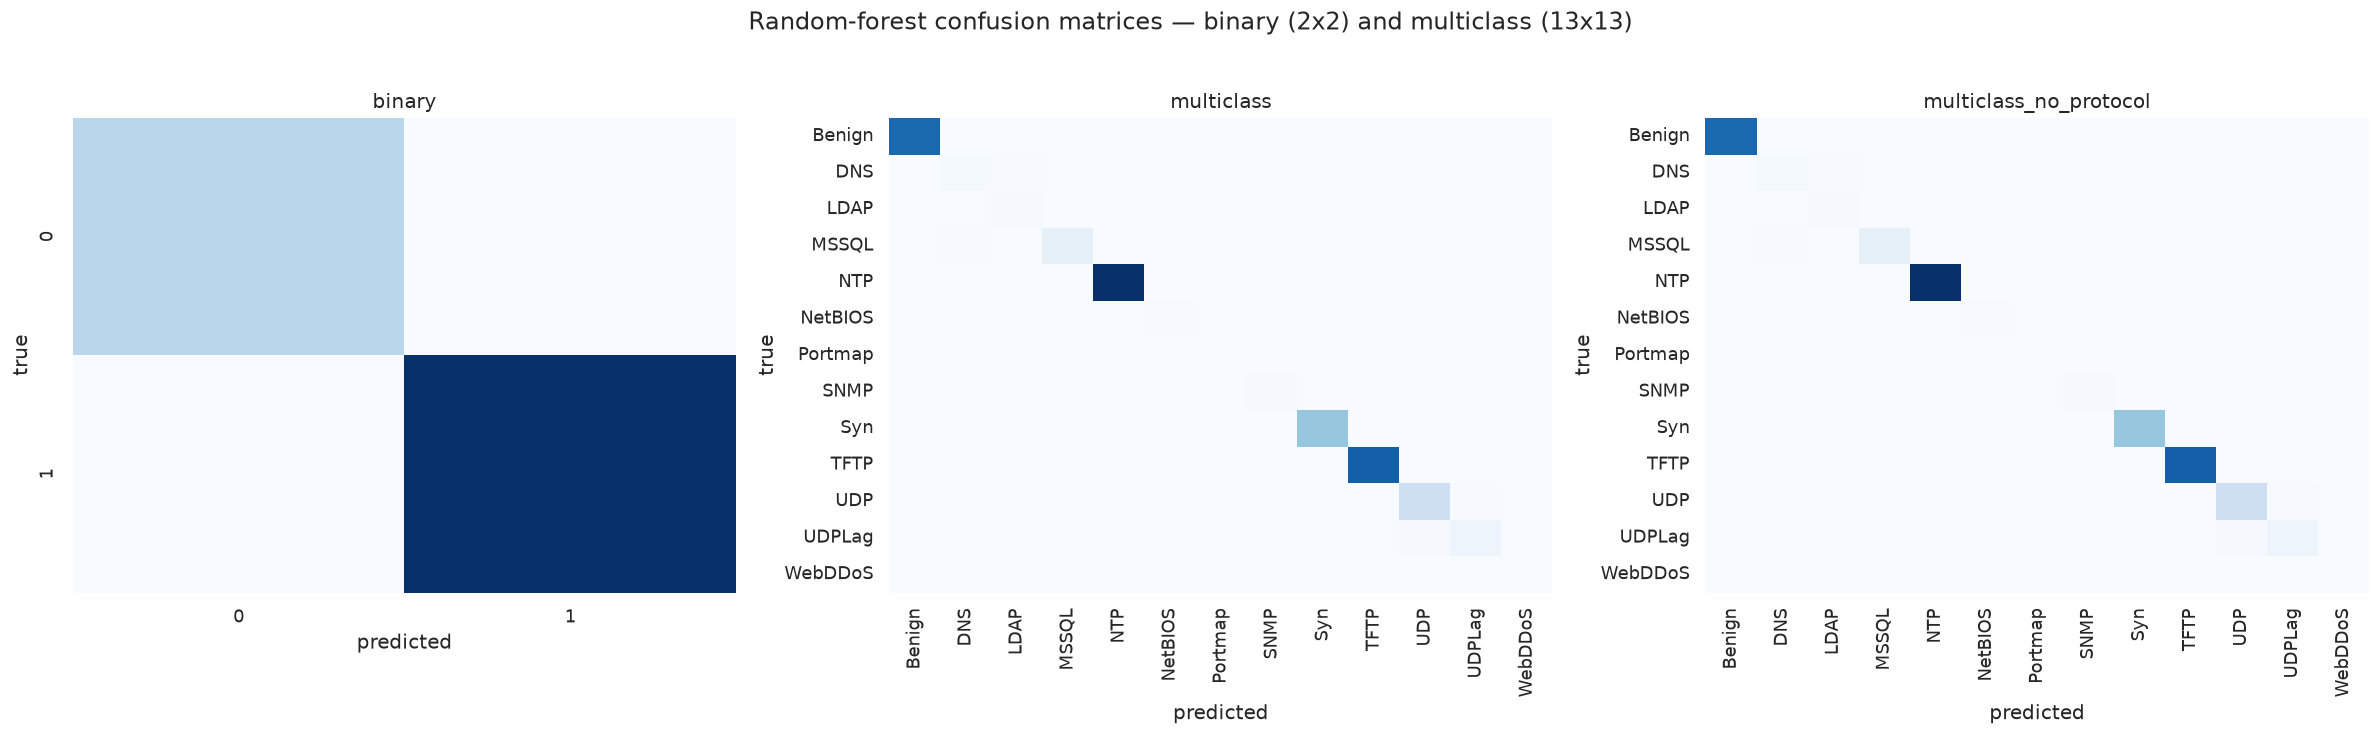

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
titles = ["binary", "multiclass", "multiclass_no_protocol"]
for ax, task in zip(axes, titles):
    matrix = pd.read_csv(
        RES / f"exp1_confusion_{task}_random_forest.csv", index_col=0
    )
    sns.heatmap(matrix, cmap="Blues", cbar=False, ax=ax)
    ax.set_title(task)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
fig.suptitle("Random-forest confusion matrices — binary (2x2) and multiclass (13x13)", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "03_exp1_confusion.png", bbox_inches="tight")
plt.show()

,delta_macro_f1_no_protocol
model,
dummy,0.0000
logreg,-0.0022
random_forest,0.0011


,recall
class,
LDAP,-0.0049
MSSQL,-0.0004
Benign,-0.0001
NTP,-0.0000
SNMP,0.0000
NetBIOS,0.0000
UDPLag,0.0000
TFTP,0.0000
WebDDoS,0.0000


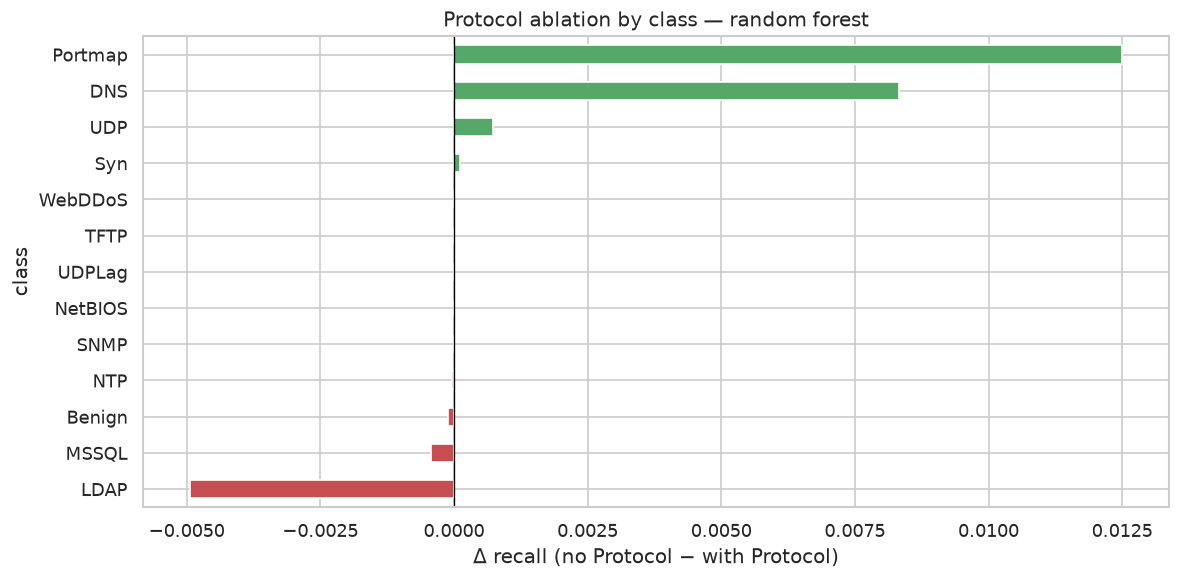

In [5]:
# Protocol ablation: does removing Protocol hurt the multiclass score?
base = results[results["task"] == "multiclass"].set_index("model")
abl = results[results["task"] == "multiclass_no_protocol"].set_index("model")
delta = (abl["macro_f1"] - base["macro_f1"]).rename("delta_macro_f1_no_protocol")
display(delta.round(4).to_frame())

base_pc = per_class[
    (per_class["task"] == "multiclass") & (per_class["model"] == "random_forest")
].set_index("class")
abl_pc = per_class[
    (per_class["task"] == "multiclass_no_protocol")
    & (per_class["model"] == "random_forest")
].set_index("class")
delta_recall = (abl_pc["recall"] - base_pc["recall"]).sort_values()
display(delta_recall.round(4).to_frame())

fig, ax = plt.subplots(figsize=(10, 5))
delta_recall.plot(kind="barh", ax=ax, color=np.where(delta_recall < 0, "#c44e52", "#55a868"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Δ recall (no Protocol − with Protocol)")
ax.set_title("Protocol ablation by class — random forest")
fig.tight_layout()
fig.savefig(FIG / "03_exp1_protocol_ablation.png", bbox_inches="tight")
plt.show()

## Verdict on H1

**Observation.** Macro-F1 falls from almost 1.0 on the binary task to roughly
0.60--0.76 for the two learned multiclass models, while Weighted-F1 stays above
0.94.  The gap between Macro-F1 and Weighted-F1 is the imbalance: rare families
are missed while the large families keep the weighted score high.  Removing
`Protocol` changes Macro-F1 by less than 0.01.

**Interprétation ML.** H1 is supported.  A model can be near-perfect at
"attack / not attack" and much weaker at "which attack".  The small protocol
delta is reassuring: the multiclass model is not merely reading the transport
protocol, because packet-size and timing features carry most of the signal.
Per-class recall is the honest view; the 13x13 confusion matrix shows which
families are merged.

**Interprétation cyber.** Q2 answer: no, a binary detector is not necessarily
useful for attack identification.  An analyst needs the family label to choose a
mitigation (SYN flood vs DNS reflection vs TFTP amplification).  A binary alarm
is a triage gate, not a classification product.  The protocol ablation suggests
the classifier is learning flow shape, but the remaining confusion between
related families is the operational limit.

**Limite.** The 13-class mapping merges `DrDoS_X` with `X`, so this experiment
does not test whether reflection and exploitation variants are separable.  That
is Experiment 2's finer-grained job.  Lab data and one seed limit external
validity.